In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.linear_model import LogisticRegression

In [ ]:
data = load_breast_cancer()
X=pd.DataFrame(
    data.data,
    columns=data.feature_names
)

y=pd.Series(
    (data.target == 0).astype(int),
    name="malignant"
)

print(y.value_counts())

print("Feature matrix Shape:", X.shape)
print("Target Shape:", y.shape)
print("Class name:", data.target_names)

malignant
0    357
1    212
Name: count, dtype: int64
Feature matrix Shape: (569, 30)
Target Shape: (569,)
Class name: ['malignant' 'benign']


       Class  Count  Probability
0  malignant    357     0.627417
1     benign    212     0.372583


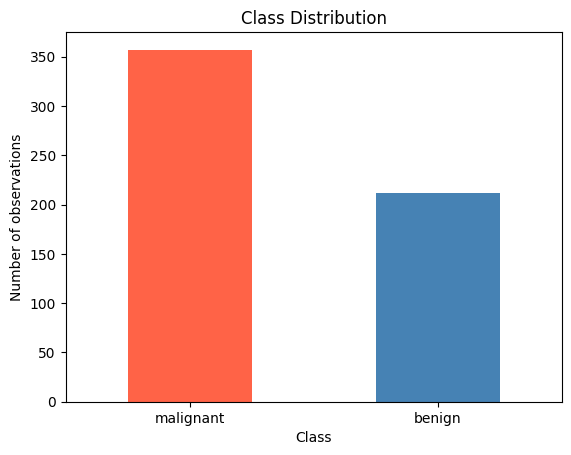

In [ ]:
class_counts = y.value_counts().sort_index()
class_distribution = pd.DataFrame({
    "Class": data.target_names,
    "Count": class_counts.values,
    "Probability": class_counts.values / len(y)
})

print(class_distribution)
class_distribution.plot(
    x="Class",
    y="Count",
    kind="bar",
    legend=False,
    color=["tomato", "steelblue"]
)
plt.ylabel("Number of observations")
plt.title("Class Distribution")
plt.xticks(rotation=0)
plt.show()

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training size:", len(y_train))
print("Testing size:", len(y_test))

print("\n Training proportions:")
print(y_train.value_counts(normalize=True).sort_index())

print("\n Testing proportions:")
print(y_test.value_counts(normalize=True).sort_index())

Training size: 455
Testing size: 114

 Training proportions:
malignant
0    0.626374
1    0.373626
Name: proportion, dtype: float64

 Testing proportions:
malignant
0    0.631579
1    0.368421
Name: proportion, dtype: float64


In [ ]:
model=make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=1000)
)

model.fit(X_train,y_train)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('logisticregression', LogisticRegression(max_iter=1000))])

In [ ]:
probabilities = model.predict_proba(X_test)

print(probabilities[:5])

[[9.99635432e-01 3.64568116e-04]
 [1.07465986e-08 9.99999989e-01]
 [9.57432053e-01 4.25679471e-02]
 [4.23812678e-01 5.76187322e-01]
 [4.90844511e-01 5.09155489e-01]]


In [ ]:
results = pd.DataFrame({"Actual_class":y_test.values,
                        "P_malignant":probabilities[:,0],
                        "P_benign":probabilities[:,1]
                        })
print(results.head(10))

   Actual_class   P_malignant  P_benign
0             0  9.996354e-01  0.000365
1             1  1.074660e-08  1.000000
2             0  9.574321e-01  0.042568
3             1  4.238127e-01  0.576187
4             0  4.908445e-01  0.509155
5             0  9.993840e-01  0.000616
6             1  2.384659e-01  0.761534
7             0  9.989878e-01  0.001012
8             0  9.994313e-01  0.000569
9             0  9.892324e-01  0.010768


In [ ]:
results["Actual_label"] = results["Actual_class"].map({0:"malignant", 1:"benign"})

print(results[["Actual_label","P_malignant","P_benign"]].head(10))

  Actual_label   P_malignant  P_benign
0    malignant  9.996354e-01  0.000365
1       benign  1.074660e-08  1.000000
2    malignant  9.574321e-01  0.042568
3       benign  4.238127e-01  0.576187
4    malignant  4.908445e-01  0.509155
5    malignant  9.993840e-01  0.000616
6       benign  2.384659e-01  0.761534
7    malignant  9.989878e-01  0.001012
8    malignant  9.994313e-01  0.000569
9    malignant  9.892324e-01  0.010768


In [ ]:
threshold = 0.5

results["Predcited_malignant"] = (results["P_malignant"] >= threshold).astype(int)

results["Predicted_label"] = results["Predcited_malignant"].map({1:"malignant", 0:"benign"})

print(results[["Actual_label","Predicted_label","P_malignant","P_benign"]].head(10))

  Actual_label Predicted_label   P_malignant  P_benign
0    malignant       malignant  9.996354e-01  0.000365
1       benign          benign  1.074660e-08  1.000000
2    malignant       malignant  9.574321e-01  0.042568
3       benign          benign  4.238127e-01  0.576187
4    malignant          benign  4.908445e-01  0.509155
5    malignant       malignant  9.993840e-01  0.000616
6       benign          benign  2.384659e-01  0.761534
7    malignant       malignant  9.989878e-01  0.001012
8    malignant       malignant  9.994313e-01  0.000569
9    malignant       malignant  9.892324e-01  0.010768


In [ ]:
for threshold in [0.3, 0.5, 0.7]:
    predictions = (results["P_malignant"] >= threshold).astype(int)

    print(f"\nThreshold: {threshold}"
          f"Predicted malignant cases: {predictions.sum()}"
    )


Threshold: 0.3Predicted malignant cases: 76

Threshold: 0.5Predicted malignant cases: 74

Threshold: 0.7Predicted malignant cases: 72


In [ ]:
actual_malignant = (y_test.values == 0).astype(int)
for threshold in [0.3, 0.5, 0.7]:
    predicted_malignant = (probabilities[:,0] >= threshold).astype(int)

    cm = confusion_matrix(actual_malignant, predicted_malignant)
    print(f"\nThreshold: {threshold}")
    print(f"Confusion Matrix:")
    print(cm)



Threshold: 0.3
Confusion Matrix:
[[38  4]
 [ 0 72]]

Threshold: 0.5
Confusion Matrix:
[[39  3]
 [ 1 71]]

Threshold: 0.7
Confusion Matrix:
[[41  1]
 [ 1 71]]


In [ ]:
Y_pred = model.predict(X_test)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print(
    "Sklearn accuracy:",
    accuracy_score(y_test, Y_pred)
)
print(
    "Sklearn precision:",
    precision_score(y_test, Y_pred)
)
print(
    "Sklearn recall:",
    recall_score(y_test, Y_pred)
)
print(
    "Sklearn f1-score:",
    f1_score(y_test, Y_pred)
)


Sklearn accuracy: 0.9649122807017544
Sklearn precision: 0.975
Sklearn recall: 0.9285714285714286
Sklearn f1-score: 0.9512195121951219


In [ ]:
threshold_metrics = pd.DataFrame(columns = ["threshold","TN","FP","FN","TP", "accuracy", "precision","sensitivity_recall", "f1-score"])
for threshold in [0.10, 0.30, 0.50, 0.70, 0.90]:
    predicted_malignant = (
        probabilities[:, 0] >= threshold
    ).astype(int)

    cm = confusion_matrix(actual_malignant, predicted_malignant)
    TN, FP, FN, TP = cm.ravel()

    accuracy = accuracy_score(actual_malignant, predicted_malignant)
    precision = precision_score(actual_malignant, predicted_malignant)
    sensitivity_recall = recall_score(actual_malignant, predicted_malignant)
    f1 = f1_score(actual_malignant, predicted_malignant)

    threshold_metrics.loc[len(threshold_metrics)] = [
        threshold, TN, FP, FN, TP,
        accuracy, precision, sensitivity_recall, f1
    ]
display(threshold_metrics.round(3))




,threshold,TN,FP,FN,TP,accuracy,precision,sensitivity_recall,f1-score
0,0.1,33.0,9.0,0.0,72.0,0.921,0.889,1.000,0.941
1,0.3,38.0,4.0,0.0,72.0,0.965,0.947,1.000,0.973
2,0.5,39.0,3.0,1.0,71.0,0.965,0.959,0.986,0.973
3,0.7,41.0,1.0,1.0,71.0,0.982,0.986,0.986,0.986
4,0.9,41.0,1.0,5.0,67.0,0.947,0.985,0.931,0.957


In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix

threshold_metrics = pd.DataFrame(
    columns=[
        "threshold", "TN", "FP", "FN", "TP",
        "accuracy", "precision",
        "sensitivity_recall", "f1-score"
    ]
)

for threshold in [0.10, 0.30, 0.50, 0.70, 0.90]:

    # Prediction using threshold
    predicted_malignant = (
        probabilities[:, 0] >= threshold
    ).astype(int)

    # Confusion Matrix
    cm = confusion_matrix(actual_malignant, predicted_malignant)

    TN, FP, FN, TP = cm.ravel()

    # ---------------- FORMULAS ----------------

    # Accuracy
    accuracy = (TP + TN) / (TP + TN + FP + FN)

    # Precision
    precision = TP / (TP + FP) if (TP + FP) != 0 else 0

    # Sensitivity / Recall
    sensitivity_recall = TP / (TP + FN) if (TP + FN) != 0 else 0

    # F1 Score
    f1 = (
        2 * precision * sensitivity_recall /
        (precision + sensitivity_recall)
        if (precision + sensitivity_recall) != 0
        else 0
    )

    # Add results
    threshold_metrics.loc[len(threshold_metrics)] = [
        threshold,
        TN,
        FP,
        FN,
        TP,
        accuracy,
        precision,
        sensitivity_recall,
        f1
    ]

display(threshold_metrics.round(3))

,threshold,TN,FP,FN,TP,accuracy,precision,sensitivity_recall,f1-score
0,0.1,33.0,9.0,0.0,72.0,0.921,0.889,1.000,0.941
1,0.3,38.0,4.0,0.0,72.0,0.965,0.947,1.000,0.973
2,0.5,39.0,3.0,1.0,71.0,0.965,0.959,0.986,0.973
3,0.7,41.0,1.0,1.0,71.0,0.982,0.986,0.986,0.986
4,0.9,41.0,1.0,5.0,67.0,0.947,0.985,0.931,0.957
